# How per-patient calibration works

This is the walkthrough behind `fig_calibration_strategy.py` — the figure that puts a
physiological equation, LightGBM and a transformer on one axis and asks which a device
should use.

**The situation.** A cuff-free device predicts blood pressure from a waveform. Pointed at a
*stranger* it is off by about **7.5 mmHg** — most of that is not noise but a fixed personal
offset, because arteries differ between people far more than they do within one person over
an afternoon. So we hand the device `k` cuff readings from this patient and let it fix
itself up. `k` is the thing the patient pays for: every reading is a cuff on an arm.

**The question the figure answers.** Given the same `k` readings, does a deep model beat a
two-parameter equation from 1904?

**The answer, in one sentence:** below about 10 readings the winner is decided by *how many
numbers you fit per patient*, not by how good the model is — and that is a statistics fact,
not a physiology one.

---

## What "calibration" is not

It is **not** retraining a network per patient. Nothing does gradient descent at the
bedside. Every method here is:

```
   ONCE, offline, on other patients        PER PATIENT, at the bedside
   ┌────────────────────────────┐         ┌──────────────────────────────┐
   │ train (or derive) a way to │ frozen  │ solve a small least-squares   │
   │ turn a waveform into       │ ──────► │ problem from k cuff readings  │
   │ numbers                    │         │ closed form, milliseconds     │
   └────────────────────────────┘         └──────────────────────────────┘
```

The methods differ **only in what the columns of that least-squares problem are, and how
many there are.** That is the whole story.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
rng = np.random.default_rng(0)

GAP = 50                              # segments skipped between calibrating and scoring
KS  = [1, 2, 3, 5, 10, 20, 50, 100]   # cuff readings on the x axis

## 1. The one function every arm shares

This is `fit_head` from [`fig_calibration_strategy.py`](../fig_calibration_strategy.py),
copied unchanged. Read the docstring carefully — it is the point of the whole notebook.

In [2]:
def calibrate(A_cal, y_cal, A_test, alpha=10.0):
    """Fit ONE patient's personal constants from their k cuff readings, then predict.

    A_cal  (k, p)  the patient's calibration segments, p numbers describing each
    y_cal  (k,)    the cuff DBP measured at those segments
    A_test (m, p)  the segments we now want to predict

    Fits p + 1 numbers (p slopes and an intercept) by ridge regression.

        p = 1    ->  the physiological equation:  DBP = a + b * (1/PTT^2)
        p = 83   ->  a linear head on hand-crafted waveform features
        p = 128  ->  a "fine-tuned" linear head on a frozen encoder's features

    Nothing else differs between the arms. Same solver, same regulariser, same k.
    """
    if len(A_cal) < 2:                     # one reading cannot fit a slope
        return np.full(len(A_test), y_cal.mean())

    mu, sd = A_cal.mean(0), A_cal.std(0)   # standardise using THIS patient only
    keep = sd > 1e-6                       # drop columns constant within the patient
    if not keep.any():
        return np.full(len(A_test), y_cal.mean())
    A_cal, A_test, mu, sd = A_cal[:, keep], A_test[:, keep], mu[keep], sd[keep]

    # alpha scaled by features-per-sample, so a wide head is regularised like a narrow one
    from sklearn.linear_model import Ridge
    a = alpha * max(1.0, A_cal.shape[1] / len(A_cal))
    return Ridge(alpha=a).fit((A_cal - mu) / sd, y_cal).predict((A_test - mu) / sd)

**The punchline is already visible.** In the real script, the equation arm and the
transformer arm call *this same function*. The equation passes a matrix with **one column**;
the transformer passes one with **128 columns**. There is no other difference — not a
different optimiser, not a different loss, not a different amount of calibration data.

So "should a device use physics or deep learning?" is, mechanically, the question **how many
columns can `k` cuff readings afford?**

## 2. The protocol, identical for every arm

For each held-out patient:

1. take their **first `k`** 10-second segments as the calibration set,
2. **skip `GAP = 50`** segments, so we never score on data adjacent to what we fitted,
3. score on **everything after that**, as mean absolute error in mmHg,
4. report the **median across the 144 held-out patients** (median, not mean, so one patient
   with an unreadable trace cannot carry the result).

The gap matters: without it, the calibration and test segments would be seconds apart and
every method would look better than it is.

In [3]:
def curve(build_A, y, rows, ks=KS):
    """Run the protocol over all patients, for each k. Returns {k: median MAE}.

    build_A(idx) -> (len(idx), p) design matrix for those segment indices.
    """
    out = {}
    for k in ks:
        per_patient = []
        for idx in rows.values():
            if k + GAP >= len(idx) - 5:      # patient too short for this k
                continue
            cal, test = idx[:k], idx[k + GAP:]
            pred = calibrate(build_A(cal), y[cal], build_A(test))
            per_patient.append(np.abs(pred - y[test]).mean())
        out[k] = float(np.median(per_patient))
    return out

## 3. The four arms, ordered by numbers-fitted-per-patient

| arm | what the columns are | numbers fitted per patient |
|---|---|---|
| cuff average | *none* — just predict the mean of the `k` readings | **1** |
| post-hoc offset | *none* — a frozen population model, shifted | **1** |
| PTT equation | one column: `1/PTT²` | **2** |
| fine-tuned head | 83 waveform features, or 128 encoder features | **84** / **129** |

### How you calibrate with an equation instead of a model

This is the part worth being concrete about, since it is the least familiar.

The equation is **Bramwell–Hill**: a stiffer artery carries the pulse faster, and pressure
stiffens the artery, so pulse transit time shortens as pressure rises. Written for fitting:

$$\mathrm{DBP} \;=\; a \;+\; b\cdot\frac{1}{\mathrm{PTT}^2}$$

`a` and `b` are **this patient's two personal constants** — their artery's geometry and
baseline stiffness. They are *not* learned from a training corpus. They are unknown until
this patient's cuff readings arrive, and they are the only thing calibration produces.

So the recipe is:

1. measure `PTT` on each of the patient's `k` calibration segments,
2. form the single column `z = 1/PTT²`,
3. solve least squares for `(a, b)` against their `k` cuff readings,
4. on every future segment, measure `PTT`, compute `z`, return `a + b·z`.

There is no neural network anywhere, and no population training step at all. Compare with
the deep arm, which is identical from step 2 onwards — it just replaces the one column `z`
with 128 columns read off a frozen encoder.

**A subtlety in the code.** The equation arm passes the design matrix as `z[:, None]` — one
column — and `calibrate` adds the intercept. That is why the table above says 2 numbers, not
1. And PTT is inverted-squared *before* fitting, not after, so the fit stays linear and has a
closed form.

In [4]:
def equation_columns(ptt):
    """The physiological equation as a design matrix: one column, 1/PTT^2.

    Bramwell-Hill is nonlinear in PTT but LINEAR in 1/PTT^2, so transforming first
    turns the per-patient fit into the same closed-form ridge solve every other arm uses.
    """
    z = 1.0 / np.clip(ptt, 0.02, None) ** 2
    return z[:, None]

## 4. Do it by hand — a step-by-step walkthrough

Everything above was description. This section is you, with a pen, doing the arithmetic the
code does. No linear algebra is needed until the very end, and that part is optional.

### The situation

**You are the device.** A patient sits down. Over a few minutes you take **4 cuff readings**,
and at each one you also measure their **pulse transit time**. Here is everything you have:

| reading | PTT (seconds) | cuff DBP (mmHg) |
|---|---|---|
| 1 | 0.2582 | 56 |
| 2 | 0.2182 | 60 |
| 3 | 0.2085 | 64 |
| 4 | 0.1857 | 68 |

Look at the pattern before doing anything: **as PTT gets shorter, pressure goes up.** That is
the physiology — higher pressure stiffens the artery, a stiffer artery carries the pulse
faster. The whole job is to pin down *how much*, for this particular person.

**Your goal** is two numbers, `a` and `b`, personal to this patient:

$$\mathrm{DBP} = a + b \times \frac{1}{\mathrm{PTT}^2}$$

Once you have them, the cuff comes off. Every future pulse gives you a PTT, and those two
numbers turn it into a pressure.

We will get there in **8 small steps**. Each one has the arithmetic written out, then a code
cell that prints the same thing so you can check yourself before moving on.

### Step 1 — turn each PTT into the feature `z`

The equation says pressure is a straight line in $1/\mathrm{PTT}^2$, not in PTT itself. So
before anything else, convert. This is the *only* place the physics enters.

$$z = \frac{1}{\mathrm{PTT}^2}$$

$$z_1 = \frac{1}{0.2582^2} = \frac{1}{0.06667} = 15
\qquad z_2 = \frac{1}{0.2182^2} = 21
\qquad z_3 = 23 \qquad z_4 = 29$$

(The PTT values were picked to make `z` land on whole numbers. Real ones will not be so
tidy.)

**Why bother?** Because a straight line is the easiest thing in the world to fit, and after
this substitution that is all we are doing. Everything from here on is generic — it would be
identical if `z` were a temperature or a share price.

In [5]:
ptt_cal = np.array([0.2582, 0.2182, 0.2085, 0.1857])   # seconds
y_cal   = np.array([56.0, 60.0, 64.0, 68.0])           # cuff DBP, mmHg

z_cal = 1.0 / ptt_cal ** 2
print("z =", np.round(z_cal, 2))

z_cal = np.array([15.0, 21.0, 23.0, 29.0])             # rounded, so the hand maths stays clean
k = len(z_cal)
print("k =", k, "readings")

z = [15. 21. 23. 29.]
k = 4 readings


### Step 2 — find the middle of the data

Here is a fact worth remembering, because it removes most of the mystery: **a line of best
fit always passes through the middle of the data.** So find the middle first, and the only
thing left to work out is the tilt.

$$\mu_z = \frac{15 + 21 + 23 + 29}{4} = \frac{88}{4} = 22
\qquad
\bar{y} = \frac{56 + 60 + 64 + 68}{4} = \frac{248}{4} = 62$$

So the line goes through the point $(z = 22,\; \mathrm{DBP} = 62)$. **You have already found
half the answer** — and notice that $\bar{y} = 62$ is exactly the "cuff average" arm from the
figure. Every other method is this number plus a tilt.

In [6]:
mu_z  = z_cal.mean()
y_bar = y_cal.mean()
print(f"mu_z  = {z_cal.sum():.0f} / {k} = {mu_z:.4g}")
print(f"y_bar = {y_cal.sum():.0f} / {k} = {y_bar:.4g}   <- this alone is the 'cuff average' arm")

mu_z  = 88 / 4 = 22
y_bar = 248 / 4 = 62   <- this alone is the 'cuff average' arm


### Step 3 — measure how spread out `z` is

Next we need a sense of scale: is a change of "2" in `z` a big move for this patient or a
tiny one? That is the standard deviation.

Subtract the middle from each value, square, average, square-root:

| $z$ | $z - \mu_z$ | $(z-\mu_z)^2$ |
|---|---|---|
| 15 | −7 | 49 |
| 21 | −1 | 1 |
| 23 | +1 | 1 |
| 29 | +7 | 49 |
| | | **sum = 100** |

$$s_z = \sqrt{\frac{100}{4}} = \sqrt{25} = 5$$

**One small gotcha.** We divided by 4, the number of readings — not by 3. Statistics courses
usually teach $n-1$; numpy's `.std()` uses $n$ by default, and that is what the code does. It
makes no difference to the final prediction here (it cancels), but if you divide by 3 by hand
your `s_z` will read 5.77 and your intermediate numbers will not match the printout.

In [7]:
dev = z_cal - mu_z
print("deviations       ", dev)
print("squared          ", dev ** 2)
print(f"sum of squares    {(dev ** 2).sum():.0f}")
print(f"divide by k       {(dev ** 2).sum() / k:.0f}")
s_z = z_cal.std()                      # numpy divides by k, not k-1
print(f"s_z = sqrt(...)   {s_z:.4g}")

deviations        [-7. -1.  1.  7.]
squared           [49.  1.  1. 49.]
sum of squares    100
divide by k       25
s_z = sqrt(...)   5


### Step 4 — rewrite `z` in units of "typical moves"

Now divide each deviation by the spread. This is the **z-score**: how many typical moves away
from the middle each reading sits.

$$z' = \frac{z - \mu_z}{s_z}$$

$$z_1' = \frac{-7}{5} = -1.4 \qquad z_2' = \frac{-1}{5} = -0.2
\qquad z_3' = +0.2 \qquad z_4' = +1.4$$

**Why do this at all?** Two reasons, and the second is the one that matters here.

1. It puts every feature on the same footing, so PTT (about 0.2) and heart rate (about 70)
   can sit in the same fit without heart rate dominating just for being a bigger number.
2. It makes the arithmetic in Step 6 collapse to a single division. Specifically, **the
   squares of the z-scores always add up to exactly `k`**:

$$1.96 + 0.04 + 0.04 + 1.96 = 4 = k \;\checkmark$$

That is not a coincidence about these numbers — it is true by construction, every time,
because dividing by the standard deviation is precisely what makes it true. Hold onto it; it
is the reason you will not need a calculator for the hard-looking part.

In [8]:
zp = (z_cal - mu_z) / s_z
print("z' =", zp)
print("z'^2 =", zp ** 2)
print(f"sum of z'^2 = {(zp ** 2).sum():.0f}   <- equals k = {k}, always, by construction")

z' = [-1.4 -0.2  0.2  1.4]
z'^2 = [1.96 0.04 0.04 1.96]
sum of z'^2 = 4   <- equals k = 4, always, by construction


### Step 5 — ask whether `z` and pressure move together

This is the heart of it, and it is more intuitive than the formula looks.

For each reading, write down two things: how far `z` sits from *its* middle, and how far the
pressure sits from *its* middle. Then **multiply them.**

- both above average → positive product
- both below average → also positive (two negatives)
- one above, one below → negative

So if the feature and the pressure genuinely rise together, every product is positive and the
total is big. If they are unrelated, the products scatter in sign and cancel toward zero.
**The sum is a measure of agreement.**

| reading | $z'$ | $y - \bar{y}$ | product |
|---|---|---|---|
| 1 | −1.4 | −6 | +8.4 |
| 2 | −0.2 | −2 | +0.4 |
| 3 | +0.2 | +2 | +0.4 |
| 4 | +1.4 | +6 | +8.4 |
| | | | **S = 17.6** |

All four products are positive, so this patient's data agrees with the physiology. Good.

In [9]:
y_dev = y_cal - y_bar
print("z'          ", zp)
print("y - y_bar   ", y_dev)
print("products    ", zp * y_dev)
S = (zp * y_dev).sum()
print(f"S = {S:.4g}   <- all four positive: the feature and the pressure agree")

z'           [-1.4 -0.2  0.2  1.4]
y - y_bar    [-6. -2.  2.  6.]
products     [8.4 0.4 0.4 8.4]
S = 17.6   <- all four positive: the feature and the pressure agree


### Step 6 — turn agreement into a slope, and decide how much to trust it

**The textbook answer** divides the agreement by the total amount of feature you had —
which, from Step 4, is exactly `k`:

$$b'_{\text{OLS}} = \frac{S}{k} = \frac{17.6}{4} = 4.4$$

That is ordinary least squares: the best-fitting line, full stop.

**But should you believe it?** It came from 4 readings, each carrying a few mmHg of cuff
error. A slope fitted from 4 noisy points is a shaky thing, and if you act on it you will
happily extrapolate someone's noise into a wrong diagnosis. So the code hedges — it adds a
number $\alpha$ to the denominator:

$$b'_{\text{ridge}} = \frac{S}{k + \alpha} = \frac{17.6}{4 + 10} = \frac{17.6}{14} = 1.2571$$

That is **ridge regression**, and $\alpha = 10$ is the `alpha=10.0` sitting in `calibrate`'s
signature. Read it as *skepticism*: the slope gets pulled toward zero — toward "just predict
the average and don't pretend to know the tilt".

**How hard does it pull?** The shrink factor is $k/(k+\alpha)$:

| readings `k` | shrink factor | slope kept |
|---|---|---|
| 2 | 2/12 | 17% |
| 4 | 4/14 | **29%** ← we are here |
| 20 | 20/30 | 67% |
| 100 | 100/110 | 91% |

**This table is the whole figure in miniature.** With few readings the method barely listens
to the data at all; with many, skepticism fades and it converges on the textbook answer. And
notice $\alpha$ is compared against `k` — so the more numbers you are trying to fit, the more
readings you need before you are trusted. That is the entire low-`k` story.

In [10]:
alpha  = 10.0                      # = 10 * max(1, p/k) = 10 * max(1, 1/4) = 10
b_ols   = S / k
b_ridge = S / (k + alpha)
print(f"b' (OLS,   S/k)       = {S:.4g} / {k}  = {b_ols:.4f}")
print(f"b' (ridge, S/(k+a))   = {S:.4g} / {k + alpha:.0f} = {b_ridge:.4f}")
print(f"shrink factor k/(k+a) = {k / (k + alpha):.4f}  -> kept {100 * k / (k + alpha):.0f}% of the slope\n")
for kk in (2, 4, 20, 100):
    print(f"  if k were {kk:>3}: keep {100 * kk / (kk + alpha):4.0f}%")

b' (OLS,   S/k)       = 17.6 / 4  = 4.4000
b' (ridge, S/(k+a))   = 17.6 / 14 = 1.2571
shrink factor k/(k+a) = 0.2857  -> kept 29% of the slope

  if k were   2: keep   17%
  if k were   4: keep   29%
  if k were  20: keep   67%
  if k were 100: keep   91%


### Step 6½ — the same thing in linear algebra, slowly

Steps 5 and 6 were a recipe: multiply, add, divide. This section shows **where that recipe
comes from**. We will go one small piece at a time, and every piece has real numbers in it.

Nothing here changes the answer. The reason to bother is that the matrix version is the
*only* version that still works when you have 128 features instead of 1 — and you will be
able to see exactly where the deep model breaks.

---

#### A. First, get rid of the intercept

Our line has two unknowns, the height $a$ and the tilt $b$. Two unknowns is twice the
bookkeeping, so let us dispose of one immediately.

Subtract the mean from the pressures:

$$\tilde{\mathbf{y}} = \mathbf{y} - \bar{y} = (56, 60, 64, 68) - 62 = (-6,\, -2,\, +2,\, +6)$$

Our features are already centred — that was Step 4, and it is why the $z'$ values came out
symmetric around zero. **When both sides are centred, the line must pass through the origin**,
so there is no height left to find. Only the tilt.

From here on there is exactly one unknown, and we will call it $w$ (it is the same thing
Step 6 called $b'$).

In [11]:
y_til = y_cal - y_bar
print("y tilde =", y_til, "   (centred: sums to", y_til.sum(), ")")
print("z'      =", zp,    "   (centred: sums to", round(zp.sum(), 10), ")")

y tilde = [-6. -2.  2.  6.]    (centred: sums to 0.0 )
z'      = [-1.4 -0.2  0.2  1.4]    (centred: sums to 0.0 )


#### B. What the matrix actually is

A matrix here is nothing but the table you already wrote down. Put the feature in a column,
one row per reading:

$$X = \begin{pmatrix} -1.4 \\ -0.2 \\ +0.2 \\ +1.4 \end{pmatrix}
\qquad
\tilde{\mathbf{y}} = \begin{pmatrix} -6 \\ -2 \\ +2 \\ +6 \end{pmatrix}$$

$X$ has **4 rows** (one per cuff reading) and **1 column** (one per feature). That shape is
the whole idea: when we get to the transformer, $X$ will have 4 rows and 128 columns. The
number of rows is what the patient gave you; the number of columns is what you are asking for.

#### C. What $Xw$ means — your predictions

Pick a tilt, say $w = 4.4$. To predict, multiply each feature value by $w$. That *is* matrix
multiplication for a one-column matrix:

$$Xw = \begin{pmatrix} -1.4 \\ -0.2 \\ +0.2 \\ +1.4 \end{pmatrix} \times 4.4
= \begin{pmatrix} -6.16 \\ -0.88 \\ +0.88 \\ +6.16 \end{pmatrix}$$

Compare against what actually happened, $\tilde{\mathbf{y}} = (-6, -2, +2, +6)$. Close on
readings 1 and 4, off by about 1.1 on readings 2 and 3.

#### D. What we are trying to make small

Subtract to get the **errors**, one per reading:

$$\tilde{\mathbf{y}} - Xw = \begin{pmatrix} -6 - (-6.16) \\ -2 - (-0.88) \\
2 - 0.88 \\ 6 - 6.16 \end{pmatrix}
= \begin{pmatrix} +0.16 \\ -1.12 \\ +1.12 \\ -0.16 \end{pmatrix}$$

Some are positive and some negative, so we cannot just add them up — they would cancel and a
terrible fit would look perfect. Square them first, then add:

$$0.16^2 + 1.12^2 + 1.12^2 + 0.16^2 = 0.0256 + 1.2544 + 1.2544 + 0.0256 = 2.56$$

**That number, 2.56, is the total squared error for $w = 4.4$.** In matrix notation "square
everything and add it up" is written $\lVert\,\cdot\,\rVert^2$, so:

$$\mathcal{L}(w) = \lVert \tilde{\mathbf{y}} - Xw \rVert^2$$

That is all the notation means. Our job is to find the $w$ that makes it smallest.

In [12]:
w_try = 4.4
pred_try = zp * w_try
err_try  = y_til - pred_try
print(f"w = {w_try}")
print(f"  Xw            {pred_try}")
print(f"  y - Xw        {err_try}")
print(f"  squared       {err_try ** 2}")
print(f"  L(w) = sum    {(err_try ** 2).sum():.4f}")

w = 4.4
  Xw            [-6.16 -0.88  0.88  6.16]
  y - Xw        [ 0.16 -1.12  1.12 -0.16]
  squared       [0.0256 1.2544 1.2544 0.0256]
  L(w) = sum    2.5600


#### E. Write $\mathcal{L}(w)$ out — it is just a parabola

Rather than guess values of $w$, expand the expression. Multiply it out term by term, exactly
as you would $(p - q)^2 = p^2 - 2pq + q^2$:

$$\mathcal{L}(w) = \underbrace{\sum \tilde{y}_i^2}_{\text{does not involve } w}
\;-\; 2w\underbrace{\sum z_i'\tilde{y}_i}_{= \;S}
\;+\; w^2\underbrace{\sum z_i'^2}_{=\;k}$$

Now put our three numbers in. We have already computed every one of them:

- $\sum \tilde{y}_i^2 = 36 + 4 + 4 + 36 = 80$
- $\sum z_i'\tilde{y}_i = S = 17.6$ — **this is Step 5**
- $\sum z_i'^2 = k = 4$ — **this is Step 4**

$$\boxed{\;\mathcal{L}(w) = 80 - 35.2\,w + 4w^2\;}$$

**Stop and look at that.** It is an ordinary parabola in one variable — the kind you could
sketch on paper. Every bit of matrix notation above was bookkeeping to arrive at this. And
the two mysterious quantities from Steps 4 and 5 turn out to be nothing more exotic than *the
coefficients of a quadratic*.

#### F. Minimise it the way you always did

A parabola is lowest where its derivative is zero. Differentiate:

$$\frac{d\mathcal{L}}{dw} = -35.2 + 8w = 0
\qquad\Longrightarrow\qquad
w = \frac{35.2}{8} = 4.4$$

**There is `S/k`.** In symbols the same two lines read $-2S + 2kw = 0$, so $w = S/k$ — which
is what Step 6 asserted without proof. The 2's cancel, which is why the recipe has no 2 in it.

In [13]:
SSy = (y_til ** 2).sum()
print(f"sum y~^2 = {SSy:.0f}     2S = {2 * S:.4g}     k = {k}")
print(f"L(w) = {SSy:.0f} - {2 * S:.4g} w + {k} w^2")
print(f"dL/dw = -{2 * S:.4g} + {2 * k} w = 0   ->   w = {2 * S:.4g} / {2 * k} = {S / k:.4f}\n")
for wv in (0.0, 1.2571, 4.4, 6.0):
    print(f"  L({wv:6.4g}) = {SSy - 2 * S * wv + k * wv ** 2:8.4f}"
          f"{'   <- minimum' if abs(wv - 4.4) < 1e-9 else ''}")

sum y~^2 = 80     2S = 35.2     k = 4
L(w) = 80 - 35.2 w + 4 w^2
dL/dw = -35.2 + 8 w = 0   ->   w = 35.2 / 8 = 4.4000

  L(     0) =  80.0000
  L( 1.257) =  42.0713
  L(   4.4) =   2.5600   <- minimum
  L(     6) =  12.8000


#### G. Ridge changes exactly one coefficient

Now the interesting part. Ridge adds a penalty for having a big tilt: $+\,\alpha w^2$, with
$\alpha = 10$. Add it to our parabola:

$$\mathcal{L}_{\text{ridge}}(w) = \underbrace{80 - 35.2w + 4w^2}_{\text{as before}} + 10w^2
= 80 - 35.2w + \mathbf{14}w^2$$

**The $w^2$ coefficient went from 4 to 14. That is the entire difference between OLS and
ridge** — nothing else in the expression moved. And 4 was $k$, so 14 is $k + \alpha$.

Differentiate again:

$$\frac{d\mathcal{L}_{\text{ridge}}}{dw} = -35.2 + 28w = 0
\qquad\Longrightarrow\qquad
w = \frac{35.2}{28} = 1.2571$$

which is the number from Step 6, now derived rather than asserted. Steepening the $w^2$ term
makes the parabola narrower, which drags its lowest point toward zero — **that is what
"shrinkage" means, geometrically.** Plot both and you can watch it happen.

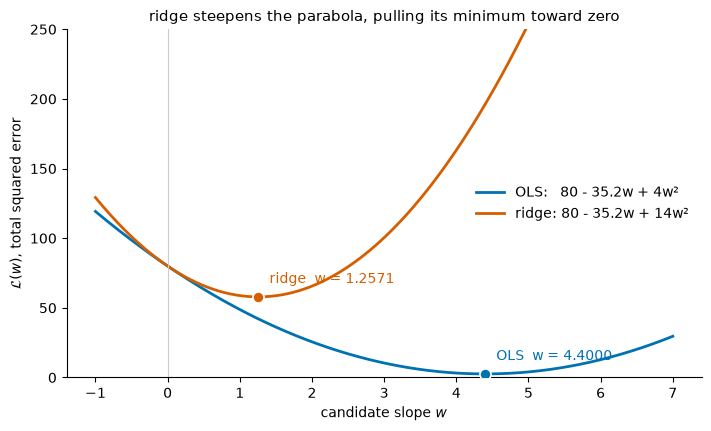

In [14]:
ws = np.linspace(-1, 7, 400)
L_ols   = SSy - 2 * S * ws + k * ws ** 2
L_ridge = SSy - 2 * S * ws + (k + alpha) * ws ** 2

fig, ax = plt.subplots(figsize=(7.0, 4.2), constrained_layout=True)
ax.plot(ws, L_ols,   color="#0072B2", lw=2, label=f"OLS:   80 - 35.2w + {k}w²")
ax.plot(ws, L_ridge, color="#D55E00", lw=2, label=f"ridge: 80 - 35.2w + {k + alpha:.0f}w²")
for wv, col, nm in ((S / k, "#0072B2", "OLS"), (S / (k + alpha), "#D55E00", "ridge")):
    Lv = SSy - 2 * S * wv + (k if nm == "OLS" else k + alpha) * wv ** 2
    ax.plot([wv], [Lv], "o", color=col, ms=8, mec="white", mew=1.2, zorder=5)
    ax.annotate(f"{nm}  w = {wv:.4f}", (wv, Lv), textcoords="offset points",
                xytext=(8, 10), color=col, fontsize=10)
ax.axvline(0, color="#CCC", lw=0.8)
ax.set_xlabel("candidate slope $w$"); ax.set_ylabel(r"$\mathcal{L}(w)$, total squared error")
ax.set_title("ridge steepens the parabola, pulling its minimum toward zero", fontsize=11)
ax.legend(frameon=False); ax.set_ylim(0, 250)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### H. Now the matrix version, which says the same thing

With one feature we could write everything with $\sum$ signs. With 128 we cannot, so here is
the identical argument in matrix notation. Compare it line by line against E and F:

| one feature (what we just did) | many features |
|---|---|
| $\sum \tilde{y}_i^2$ | $\tilde{\mathbf{y}}^\top\tilde{\mathbf{y}}$ |
| $S = \sum z_i'\tilde{y}_i$ | $X^\top\tilde{\mathbf{y}}$ |
| $k = \sum z_i'^2$ | $X^\top X$ |
| $\mathcal{L} = 80 - 2Sw + kw^2$ | $\mathcal{L} = \tilde{\mathbf{y}}^\top\tilde{\mathbf{y}} - 2\mathbf{w}^\top X^\top\tilde{\mathbf{y}} + \mathbf{w}^\top X^\top X\mathbf{w}$ |
| $\dfrac{d\mathcal{L}}{dw} = -2S + 2kw$ | $\dfrac{\partial\mathcal{L}}{\partial \mathbf{w}} = -2X^\top\tilde{\mathbf{y}} + 2X^\top X\mathbf{w}$ |
| set to 0: $kw = S$ | set to 0: $X^\top X\mathbf{w} = X^\top\tilde{\mathbf{y}}$ |

That last line is called the **normal equations**, and it is the whole of least squares. With
ridge, $\alpha$ joins the diagonal:

$$(X^\top X + \alpha I)\,\mathbf{w} = X^\top\tilde{\mathbf{y}}$$

With one feature, "the diagonal" was the single number $k$, and adding $\alpha$ to it was the
$4 \to 14$ you saw in G. **That is literally why the method is called *ridge*: you raise a
ridge along the diagonal of $X^\top X$.**

In [15]:
X    = zp[:, None]                      # 4x1: four readings, one feature
ytil = y_til[:, None]                   # 4x1

XtX = X.T @ X                           # 1x1, and it contains k
Xty = X.T @ ytil                        # 1x1, and it contains S
print(f"X is {X.shape[0]} rows x {X.shape[1]} column")
print(f"X^T X = {XtX[0, 0]:.4g}    <- the k from Step 4")
print(f"X^T y = {Xty[0, 0]:.4g} <- the S from Step 5\n")

w_ols   = np.linalg.solve(XtX, Xty)                       # normal equations
w_ridge = np.linalg.solve(XtX + alpha * np.eye(1), Xty)   # alpha on the diagonal
print(f"OLS    solve(X^T X,        X^T y) = {w_ols[0, 0]:.4f}")
print(f"ridge  solve(X^T X + aI,   X^T y) = {w_ridge[0, 0]:.4f}")
assert np.isclose(w_ols[0, 0], b_ols) and np.isclose(w_ridge[0, 0], b_ridge)
print("both match Steps 6 and G ✓")

X is 4 rows x 1 column
X^T X = 4    <- the k from Step 4
X^T y = 17.6 <- the S from Step 5

OLS    solve(X^T X,        X^T y) = 4.4000
ridge  solve(X^T X + aI,   X^T y) = 1.2571
both match Steps 6 and G ✓


#### I. Why standardising was worth the trouble

One last payoff, and it is the reason Step 4 exists.

With $p$ features, $X^\top X$ is a $p \times p$ table whose entry in row $i$, column $j$ is
$\sum_n z'_{ni} z'_{nj}$. For standardised columns that is exactly $k$ times the
**correlation** between feature $i$ and feature $j$. So:

$$X^\top X = k\,R \qquad\text{where } R \text{ is the feature correlation matrix}$$

$R$ has 1's all down its diagonal, always — a feature is perfectly correlated with itself. So
the diagonal of $X^\top X$ is $k$ in every arm of the figure, and

$$\mathbf{w} = (kR + \alpha I)^{-1} X^\top \tilde{\mathbf{y}}$$

**One formula covers every method in this notebook.** The equation arm has $R = (1)$, a 1×1
matrix holding the number 1, so $kR + \alpha I = k + \alpha = 14$ and you divide — exactly
what you did by hand. The transformer has $R$ at 128×128 and you invert.

**And this tells you precisely when the deep arm breaks.** The diagonal is fixed at $k$, so
the only thing that differs between arms is **how correlated the features are with each
other** — the off-diagonal entries of $R$. Features that duplicate one another push $R$ toward
singular, $(kR + \alpha I)^{-1}$ blows up, and the fitted weights swing wildly to cancel each
other. An encoder's 128 features are heavily redundant by construction; ask them to split the
evidence from $k = 2$ cuff readings and $R$ is hopelessly rank-deficient. **The only reason
the inverse exists at all is the $\alpha I$ propping up the diagonal** — which is the same
$\alpha$ that flattened your parabola in panel G, doing the same job for the same reason.

In [16]:
A2  = np.c_[z_cal, np.array([69.0, 63.0, 77.0, 71.0])]   # add heart rate as a 2nd feature
Ap2 = (A2 - A2.mean(0)) / A2.std(0)
R   = np.corrcoef(Ap2.T)

print(f"X^T X =\n{np.round(Ap2.T @ Ap2, 4)}")
print(f"\nR (correlation) =\n{np.round(R, 4)}")
print(f"\nk * R =\n{np.round(k * R, 4)}")
assert np.allclose(Ap2.T @ Ap2, k * R), "X^T X = k R identity failed"
print("\nX^T X = k * R ✓   (diagonal is k = 4; only the off-diagonal carries the redundancy)")

print("\n--- what redundancy does to the inverse ---")
for rho in (0.0, 0.28, 0.9, 0.999, 1.0):
    Rr = np.array([[1.0, rho], [rho, 1.0]])
    G0 = k * Rr                                   # no alpha
    Ga = k * Rr + alpha * np.eye(2)               # with alpha
    d0 = np.linalg.det(G0)
    print(f"  corr {rho:5.3f}   det(kR) = {d0:7.4f}   "
          f"{'SINGULAR - no inverse' if abs(d0) < 1e-9 else f'det(kR+aI) = {np.linalg.det(Ga):8.3f}'}")

X^T X =
[[4.   1.12]
 [1.12 4.  ]]

R (correlation) =
[[1.   0.28]
 [0.28 1.  ]]

k * R =
[[4.   1.12]
 [1.12 4.  ]]

X^T X = k * R ✓   (diagonal is k = 4; only the off-diagonal carries the redundancy)

--- what redundancy does to the inverse ---
  corr 0.000   det(kR) = 16.0000   det(kR+aI) =  196.000
  corr 0.280   det(kR) = 14.7456   det(kR+aI) =  194.746
  corr 0.900   det(kR) =  3.0400   det(kR+aI) =  183.040
  corr 0.999   det(kR) =  0.0320   det(kR+aI) =  180.032
  corr 1.000   det(kR) =  0.0000   SINGULAR - no inverse


### Step 7 — make a prediction

You now have everything. The line passes through the middle $(\mu_z, \bar{y})$ and tilts by
$b'$ per z-score:

$$\hat{y}(z) = \bar{y} + b' \times \frac{z - \mu_z}{s_z}$$

A new pulse arrives with **PTT = 0.20 s**, so $z = 1/0.20^2 = 25$. Walk it through:

$$\frac{25 - 22}{5} = 0.6 \text{ z-scores above the middle}$$
$$\hat{y} = 62 + 1.2571 \times 0.6 = 62 + 0.7543 = \mathbf{62.754 \text{ mmHg}}$$

**A free check on your work.** Predict at $z = 22$ — the middle itself. The z-score is 0, so
the tilt contributes nothing and the answer must be exactly $\bar{y} = 62$. If yours is not,
the error is in Step 2 or Step 4.

In [17]:
def predict_by_hand(z_new):
    return y_bar + b_ridge * (z_new - mu_z) / s_z

z_new = np.array([25.0, 22.0, 31.0])
for zz in z_new:
    print(f"z = {zz:5.1f}  ->  z-score {(zz - mu_z) / s_z:+.2f}  ->  {predict_by_hand(zz):.4f} mmHg")

print("\n--- the code, for comparison ---")
code_out = calibrate(z_cal[:, None], y_cal, z_new[:, None])
print("by hand  ", np.round(predict_by_hand(z_new), 5))
print("calibrate", np.round(code_out, 5))
assert np.allclose(predict_by_hand(z_new), code_out), "hand calculation and calibrate() disagree"
print("match ✓  -- you just reproduced the equation arm of the figure")

z =  25.0  ->  z-score +0.60  ->  62.7543 mmHg
z =  22.0  ->  z-score +0.00  ->  62.0000 mmHg
z =  31.0  ->  z-score +1.80  ->  64.2629 mmHg

--- the code, for comparison ---


by hand   [62.75429 62.      64.26286]
calibrate [62.75429 62.      64.26286]
match ✓  -- you just reproduced the equation arm of the figure


### Step 8 — recover the patient's two personal constants

The prediction works, but it is still written in z-scores, which no clinician wants to see.
Multiply out to get back to the form we set out to fill in:

$$\hat{y} = \underbrace{\left(\bar{y} - \frac{b'\mu_z}{s_z}\right)}_{a}
\;+\; \underbrace{\frac{b'}{s_z}}_{b} \times z$$

$$b = \frac{1.2571}{5} = 0.2514
\qquad
a = 62 - \frac{1.2571 \times 22}{5} = 62 - 5.531 = 56.469$$

**This patient's equation, complete:**

$$\boxed{\;\mathrm{DBP} \;=\; 56.47 \;+\; \frac{0.2514}{\mathrm{PTT}^2}\;}$$

Check it end to end, straight from a raw PTT with no z-scores anywhere:

$$56.469 + \frac{0.2514}{0.20^2} = 56.469 + 6.286 = 62.754 \;\checkmark$$

Those two numbers are what "calibrating with the equation" produces. They belong to this
person — the next patient gets different ones. And that is the honest answer to *how do you
use an equation instead of a model*: **you just did, in eight steps, with a pen.** The deep
version differs only in that Step 5 gets repeated for 128 columns instead of 1, and Step 6
becomes a matrix inverse instead of a division.

---

**One thing that will look wrong, and isn't.** Run the cell and feed it the *original*
calibration PTTs. Reading 1 was 0.2582 s with a cuff value of **56**, but the equation now
says **60.2**. Reading 4 was 68 and the equation says 63.8. It does not reproduce the very
data it was fitted on — so did we make a mistake?

No: this is Step 6 doing exactly its job. We kept only 29% of the slope, so the fitted line
is deliberately flatter than the four points, and everything is pulled toward the average of
62. **Ridge does not promise to pass through your data; it promises not to over-trust it.**

If that still feels wrong, it is worth knowing that the instinct is correct in a world with
plenty of data and wrong in this one. With 4 noisy cuff readings, a line that hits all four
points exactly is fitting the cuff's measurement error as if it were physiology, and it will
predict *worse* on the patient's next reading than the flattened line does. Exercise 1 in
"Your turn" below lets you set $\alpha = 0$ and watch the line snap onto the data — that is
the version that looks right and performs worse.

In [18]:
b_phys = b_ridge / s_z
a_phys = y_bar - b_ridge * mu_z / s_z
print(f"b = {b_ridge:.4f} / {s_z:.4g} = {b_phys:.6f}")
print(f"a = {y_bar:.4g} - {b_ridge:.4f} * {mu_z:.4g} / {s_z:.4g} = {a_phys:.6f}")
print(f"\n    DBP = {a_phys:.2f} + {b_phys:.4f} / PTT^2\n")

for p_ in (0.20, 0.2582, 0.1857):
    print(f"PTT {p_:.4f} s -> {a_phys + b_phys / p_ ** 2:.3f} mmHg")
assert np.isclose(a_phys + b_phys / 0.20 ** 2, 62.754285714), "physical form disagrees"
print("\nsame 62.754 as Step 7, from a raw PTT ✓")

b = 1.2571 / 5 = 0.251429
a = 62 - 1.2571 * 22 / 5 = 56.468571

    DBP = 56.47 + 0.2514 / PTT^2

PTT 0.2000 s -> 62.754 mmHg
PTT 0.2582 s -> 60.240 mmHg
PTT 0.1857 s -> 63.760 mmHg

same 62.754 as Step 7, from a raw PTT ✓


### Recap — the entire method in six lines

```
1.  z      = 1 / PTT^2                      turn timing into a feature
2.  mu, ybar = mean(z), mean(y)             find the middle
3.  s      = std(z)                         find the spread
4.  z'     = (z - mu) / s                   rescale to z-scores   [sum z'^2 = k]
5.  S      = sum( z' * (y - ybar) )         do they move together?
6.  b'     = S / (k + alpha)                slope, hedged by skepticism
    predict: ybar + b' * (z_new - mu) / s
```

Six lines, and one of them is the physics. Everything else is generic curve-fitting you could
run on any two columns of numbers.

### Why $1/\mathrm{PTT}^2$? What about $K_1/\mathrm{PTT} + K_2$?

Step 1 asserted the transform and moved on. It deserves better, because you will meet at
least three different forms in the literature and they all claim to be *the* equation.

**Where the square comes from.** Two classical results, chained:

*Moens–Korteweg* relates pulse wave velocity to how stiff the vessel is:

$$\mathrm{PWV} = \sqrt{\frac{E\,h}{\rho\,d}}
\qquad\Longrightarrow\qquad E \;\propto\; \mathrm{PWV}^2$$

($E$ = elastic modulus, $h$ = wall thickness, $d$ = diameter, $\rho$ = blood density.) Velocity
is distance over time, $\mathrm{PWV} = L/\mathrm{PTT}$, so

$$E \;\propto\; \frac{L^2}{\mathrm{PTT}^2} \;\propto\; \frac{1}{\mathrm{PTT}^2}$$

**The square is not a modelling choice — it falls out of Moens–Korteweg,** which has a
velocity *squared* in it. Everything after this point is about the second link in the chain:
how stiffness $E$ relates to pressure $P$. And *that* is where the competing forms come from:

| assumption about $E(P)$ | resulting equation | who uses it |
|---|---|---|
| $E$ **linear** in $P$: $E \approx E_0(1 + \gamma P)$ | $P = a + b/\mathrm{PTT}^2$ | this repo |
| $E$ **exponential** in $P$ (Hughes): $E = E_0 e^{\zeta P}$ | $P = a + b\ln(1/\mathrm{PTT})$ | the "log" papers |
| — none, chosen empirically — | $P = K_1/\mathrm{PTT} + K_2$ | many wearable papers |

So your $K_1/\mathrm{PTT} + K_2$ is the odd one out: it has **no clean derivation** from
Moens–Korteweg. It is a first-order empirical form, popular because it fits about as well and
is one character simpler to write. It is not wrong, it is just not derived.

**Does the choice actually matter?** This is the part worth testing rather than arguing
about, so the cell below fits all four forms to the same 4 readings.

In [19]:
forms = {"1/PTT^2  (this repo)": lambda p_: 1.0 / p_ ** 2,
         "1/PTT    (K1/PTT+K2)": lambda p_: 1.0 / p_,
         "ln(1/PTT)  (Hughes) ": lambda p_: np.log(1.0 / p_),
         "PTT itself (no form)": lambda p_: p_.copy()}

ptt_new = 1.0 / np.sqrt(z_new)          # the same test points, back in seconds
span = 100 * (ptt_cal.max() - ptt_cal.min()) / ptt_cal.mean()
print(f"this patient's PTT ranges {ptt_cal.min():.4f}-{ptt_cal.max():.4f} s  ({span:.0f}% of its mean)\n")

inside = [z_cal.min() <= zz <= z_cal.max() for zz in z_new]
print("test points:  " + "  ".join(
    f"z={zz:.0f} {'(inside)' if ok else '(EXTRAPOLATING)'}" for zz, ok in zip(z_new, inside)) + "\n")

base, preds = None, {}
for nm, f in forms.items():
    zc = f(ptt_cal)
    zs = (zc - zc.mean()) / zc.std()                     # the z' this form produces
    base = zs if base is None else base
    preds[nm] = calibrate(zc[:, None], y_cal, f(ptt_new)[:, None])
    print(f"{nm}  r vs 1/PTT^2 {np.corrcoef(base, zs)[0, 1]:+.4f}   "
          f"predictions {np.round(preds[nm], 3)}")

P = np.array(list(preds.values()))
print("\nspread across the four forms, per test point:")
for j, (zz, ok) in enumerate(zip(z_new, inside)):
    print(f"  z={zz:5.1f} {'inside ' if ok else 'OUTSIDE'}  "
          f"{P[:, j].max() - P[:, j].min():.3f} mmHg")

this patient's PTT ranges 0.1857-0.2582 s  (33% of its mean)

test points:  z=25 (inside)  z=22 (inside)  z=31 (EXTRAPOLATING)

1/PTT^2  (this repo)  r vs 1/PTT^2 +1.0000   predictions [62.754 62.    64.263]
1/PTT    (K1/PTT+K2)  r vs 1/PTT^2 +0.9985   predictions [62.791 62.072 64.108]
ln(1/PTT)  (Hughes)   r vs 1/PTT^2 +0.9939   predictions [62.817 62.143 63.951]
PTT itself (no form)  r vs 1/PTT^2 -0.9865   predictions [62.834 62.21  63.797]

spread across the four forms, per test point:
  z= 25.0 inside   0.079 mmHg
  z= 22.0 inside   0.210 mmHg
  z= 31.0 OUTSIDE  0.466 mmHg


**Inside the calibration range, they are the same fit.** Across a 33% swing in PTT — wider
than most patients show during a calibration window — every form correlates with
$1/\mathrm{PTT}^2$ at $|r| \ge 0.986$ once standardised, and at $z = 25$ the four predictions
span **0.08 mmHg**. Even *raw PTT with no transform at all* is in that spread (with a negative
slope, since it runs the other way). Against a cuff whose own repeatability is ±5 mmHg, that
is nothing.

**Outside it, they separate — and the cell shows exactly that.** The third test point, $z =
31$, sits beyond the calibration range of 15–29. There the spread grows to **0.47 mmHg**,
roughly six times the in-range disagreement, and the ordering is systematic rather than
noisy: the more curvature a form has, the higher it predicts. That is the whole argument for
the derived form in one line — *the transforms agree where you have data and disagree where
you do not*, which is precisely where you would want to be able to trust one. Widen the range
to a full physiological 0.12–0.32 s and $1/\mathrm{PTT}$ still tracks $1/\mathrm{PTT}^2$ at
$r = 0.992$, but the residual disagreement is all at the ends.

**Why they collapse together.** Any smooth monotonic function is approximately a straight line
over a short enough interval — that is just a first-order Taylor expansion. One patient's
calibration window *is* a short interval, so $1/\mathrm{PTT}$, $1/\mathrm{PTT}^2$ and
$\ln\mathrm{PTT}$ are near-linear reparametrisations of each other across it. And Step 4
standardises the feature, which throws away scale and offset — the only things that
distinguish them. The functional form is being flattened out before the fit even starts.

**So when does it matter?**

- **Not** for per-patient calibration, which is this entire notebook. Pick whichever you like;
  the repo's own sweep found PTT explains only 4–5% of within-subject DBP variance *under
  every transform tested*, including with invasive arterial-line PTT.
- **Yes** for extrapolating well outside the calibration range — the forms diverge sharply
  once you leave the window they were fitted in, and $1/\mathrm{PTT}^2$ is the one with the
  derivation behind it.
- **Yes** for population fits spanning many patients and a wide pressure range, where the
  interval is no longer short and the curvature is real.
- **Yes** if you want the fitted $b$ to carry physical units and be comparable across studies,
  rather than just being a number that makes the prediction come out right.

The honest summary: **the square is well-derived and costs nothing, so use it — but do not
expect it to buy you accuracy over $K_1/\mathrm{PTT} + K_2$ in a per-patient fit, because it
does not.**

### The offset arm has only two steps

The method that *wins* the shaded band on the real figure is even simpler. There is no
feature, no spread, no $\alpha$, no slope. You have a frozen model that already predicts
pressure; you are only asking **how wrong is it for this person, on average?**

**Step 1.** For each calibration reading, subtract what the model said from what the cuff
said:

| cuff $y$ | model $\hat{p}$ | residual |
|---|---|---|
| 56 | 59 | −3 |
| 60 | 61 | −1 |
| 64 | 63 | +1 |
| 68 | 67 | +1 |
| | | **sum = −2** |

**Step 2.** Average them, and that is your correction:

$$\text{offset} = \frac{-2}{4} = -0.5 \text{ mmHg}$$

From now on, take whatever the model says and subtract 0.5. That is the whole algorithm —
**and on real data, below 5 cuff readings, it beats a transformer.** Worth sitting with,
given how much of this notebook is spent on the alternatives.

In [20]:
pop_cal  = np.array([59.0, 61.0, 63.0, 67.0])   # what the frozen population model predicted
pop_test = np.array([64.0, 62.0, 70.0])         # its predictions on future segments

residuals = y_cal - pop_cal
offset    = residuals.mean()
print("residuals (cuff - model):", residuals)
print(f"offset = {residuals.sum():.0f} / {k} = {offset:+.4g} mmHg\n")
print("model said      ", pop_test)
print("calibrated      ", pop_test + offset)

residuals (cuff - model): [-3. -1.  1.  1.]
offset = -2 / 4 = -0.5 mmHg

model said       [64. 62. 70.]
calibrated       [63.5 61.5 69.5]


### Optional — what changes with two columns

Only read this if Steps 1–8 feel solid. Nothing later depends on it.

Suppose you add heart rate as a second column. Steps 1–5 are unchanged, you just do them
twice — once per column — giving you **two** agreement numbers instead of one:

$$S_z = \textstyle\sum z'(y - \bar y) = 17.6, \qquad S_h = \sum h'(y - \bar y) = 8.0$$

Step 6 is where it differs. With one column you divided by $k + \alpha$. With two, you must
also account for the fact that the columns might be **telling you the same thing twice** — if
heart rate rises whenever `z` rises, you must not count that evidence once for each. So you
need one more number, the agreement *between the two features*:

$$c = \textstyle\sum z' h' = 1.12$$

And the single division becomes a 2×2 solve:

$$\begin{pmatrix} k+\alpha & c \\ c & k+\alpha \end{pmatrix}
\begin{pmatrix} w_1 \\ w_2 \end{pmatrix}
= \begin{pmatrix} S_z \\ S_h \end{pmatrix}$$

Notice the diagonal is $k + \alpha = 14$ — the *same* denominator as before, because Step 4's
trick still holds for each column. Only the off-diagonal is new. Solving by hand:

$$\det = 14^2 - 1.12^2 = 194.75$$
$$w_1 = \frac{14(17.6) - 1.12(8.0)}{194.75} = 1.2192, \qquad
  w_2 = \frac{14(8.0) - 1.12(17.6)}{194.75} = 0.4739$$

**Here is the payoff — the reason this section is worth reading.** With $c = 1.12$ against a
diagonal of 14, the two features barely overlap, so each keeps nearly all of its own slope.
But watch what happens as the features become redundant: $c$ climbs toward $k$, the
determinant $\left((k+\alpha)^2 - c^2\right)$ collapses, and the two slopes start swinging
wildly in opposite directions to cancel each other out.

**That is the 128-column failure mode, and you can see it in a 2×2 determinant.** An encoder's
features are highly redundant with one another; ask 128 of them to split the evidence from 2
cuff readings and you get exactly this instability — which is why the transformer is the worst
arm at `k = 2` on the real figure.

In [21]:
hr_cal  = np.array([69.0, 63.0, 77.0, 71.0])
hr_test = np.array([74.0, 70.0, 66.0])

A = np.c_[z_cal, hr_cal]                      # two columns now
B = np.c_[z_new, hr_test]

muA, sdA = A.mean(0), A.std(0)
Ap = (A - muA) / sdA                          # Step 4, done per column
p  = A.shape[1]
alpha2 = 10.0 * max(1.0, p / k)               # still 10 here, since p < k

G = Ap.T @ Ap + alpha2 * np.eye(p)            # [[k+a, c], [c, k+a]]
r = Ap.T @ (y_cal - y_bar)                    # [S_z, S_h]
w = np.linalg.solve(G, r)

print("h' =", (hr_cal - hr_cal.mean()) / hr_cal.std())
print(f"c  = {Ap[:, 0] @ Ap[:, 1]:.4f}      (vs diagonal {k + alpha2:.0f}: barely redundant)")
print(f"G  = {G.tolist()}")
print(f"r  = [S_z, S_h] = {r}")
print(f"det = {np.linalg.det(G):.4f}")
print(f"w  = {np.round(w, 6)}\n")

hand2 = y_bar + ((B - muA) / sdA) @ w
code2 = calibrate(A, y_cal, B)
print("by hand  ", np.round(hand2, 5))
print("calibrate", np.round(code2, 5))
assert np.allclose(hand2, code2), "hand calculation and calibrate() disagree"
print("match ✓")

h' = [-0.2 -1.4  1.4  0.2]
c  = 1.1200      (vs diagonal 14: barely redundant)
G  = [[14.0, 1.1199999999999999], [1.1199999999999999, 14.0]]
r  = [S_z, S_h] = [17.6  8. ]
det = 194.7456
w  = [1.219232 0.47389 ]

by hand   [63.11065 62.      63.8155 ]
calibrate [63.11065 62.      63.8155 ]
match ✓


### Your turn

Change one thing, predict the answer, then run it. Working out *why* you were wrong is where
the intuition actually forms.

1. **Set `alpha = 0`** and redo Step 6. The slope jumps from 1.2571 to the OLS value 4.4, and
   the prediction at $z=25$ moves from 62.75 to **64.64**. That 1.9 mmHg gap *is* the
   regularisation — the difference between believing 4 readings and hedging against them.

2. **Keep only 2 readings** (`z_cal[:2]`, `y_cal[:2]`). The shrink factor falls to $2/12$, so
   ridge keeps a sixth of the slope instead of 29%. You are watching the low-`k` collapse
   happen in a single division.

3. **Make heart rate an exact copy of `z_cal`** in the two-column cell. Now $c \to k$, the
   determinant collapses toward $\alpha(\alpha + 2k)$, and the two slopes split what was one
   slope's worth of evidence. This is the redundancy problem, staged deliberately.

4. **Add 3 mmHg to one cuff reading** — say reading 1 becomes 59. Recompute `S` and watch how
   much the slope moves. This is why the code is skeptical: a single mis-cuffed reading, out
   of 4, visibly bends the patient's personal constants.

## 5. Why fitting more numbers loses when `k` is small

A simulation, so the mechanism is visible rather than asserted. 60 patients, 400 segments
each. Diastolic pressure depends on **three** things: arterial stiffness (which PTT sees),
heart rate, and a third waveform driver `w` — plus 2.5 mmHg of measurement noise.

The two arms differ in what they can see, which is the honest caricature of the real
comparison:

- the **population model** (standing in for LightGBM) is built on `z` and `hr` only — it is
  blind to `w`, exactly as a hand-built feature set is blind to whatever an encoder found;
- the **rich features** (standing in for the encoder) have **30 columns**: all 3 real drivers
  and 27 that are pure noise, since most of an encoder's 128 dimensions carry nothing about
  *this* patient's pressure.

So the deep arm really does hold information the others lack. The question is what it costs
to extract it.

In [22]:
N_PAT, N_SEG, P_RICH = 60, 400, 30

# each patient's own constants -- the between-subject spread calibration exists to remove
pat_a  = rng.normal(58.0, 9.0,  N_PAT)    # personal baseline DBP (mmHg)
pat_b  = rng.normal(1.00, 0.35, N_PAT)    # personal stiffness constant
pat_hr = rng.normal(0.08, 0.03, N_PAT)    # personal heart-rate sensitivity
pat_w  = rng.normal(2.50, 0.50, N_PAT)    # personal sensitivity to the third driver

z   = rng.normal(20.0, 3.0, (N_PAT, N_SEG))             # 1/PTT^2, within-subject swing
hr  = rng.normal(70.0, 8.0, (N_PAT, N_SEG))             # bpm
w   = rng.normal(0.0,  1.0, (N_PAT, N_SEG))             # the third driver, PTT cannot see it
ptt = 1.0 / np.sqrt(z)
dbp = (pat_a[:, None] + pat_b[:, None] * z + pat_hr[:, None] * (hr - 70.0)
       + pat_w[:, None] * w + rng.normal(0, 2.5, (N_PAT, N_SEG)))

# the "encoder features": 3 real drivers, 27 dimensions of noise
rich = np.concatenate([z[..., None], hr[..., None], w[..., None],
                       rng.normal(0, 1, (N_PAT, N_SEG, P_RICH - 3))], axis=2)

print(f"between-patient SD of DBP  {dbp.mean(1).std():5.2f} mmHg   <- what calibration removes")
print(f"within-patient  SD of DBP  {dbp.std(1).mean():5.2f} mmHg   <- what is left to predict")

between-patient SD of DBP  10.12 mmHg   <- what calibration removes
within-patient  SD of DBP   4.78 mmHg   <- what is left to predict


A frozen population model, trained on *other* patients, stands in for LightGBM. It learns
the average relationship, so on a new patient it is wrong in two ways: by that person's
personal offset — which one number can fix — and by their personal *slopes*, which it cannot.

In [23]:
# population model: one global linear fit on (z, hr) only, leaving each test patient out.
# It never sees w -- that is the headroom the rich head will eventually exploit.
def population_prediction(i):
    others = [j for j in range(N_PAT) if j != i]
    X = np.concatenate([np.c_[z[j], hr[j]] for j in others])
    Y = np.concatenate([dbp[j] for j in others])
    c = np.linalg.lstsq(np.c_[np.ones(len(X)), X], Y, rcond=None)[0]
    return c[0] + c[1] * z[i] + c[2] * hr[i]

pop = np.stack([population_prediction(i) for i in range(N_PAT)])
print(f"population model on a stranger, no calibration: "
      f"{np.median([np.abs(pop[i] - dbp[i]).mean() for i in range(N_PAT)]):.2f} mmHg")

population model on a stranger, no calibration: 6.70 mmHg


In [24]:
SIM_KS = [1, 2, 3, 5, 10, 20, 50, 100]

def sim_curve(kind):
    out = {}
    for k in SIM_KS:
        errs = []
        for i in range(N_PAT):
            cal  = np.arange(k)
            test = np.arange(k + GAP, N_SEG)
            if kind == "cuff average":                       # 1 number
                pred = np.full(len(test), dbp[i, cal].mean())
            elif kind == "offset":                           # 1 number, on a frozen model
                pred = pop[i, test] + (dbp[i, cal] - pop[i, cal]).mean()
            elif kind == "equation":                         # 2 numbers
                pred = calibrate(equation_columns(ptt[i, cal]), dbp[i, cal],
                                 equation_columns(ptt[i, test]))
            elif kind == "rich head":                        # 31 numbers
                pred = calibrate(rich[i, cal], dbp[i, cal], rich[i, test])
            errs.append(np.abs(pred - dbp[i, test]).mean())
        out[k] = float(np.median(errs))
    return out

sim = {n: sim_curve(n) for n in ("cuff average", "offset", "equation", "rich head")}

print(f"{'k':>4}  " + "  ".join(f"{n:>13}" for n in sim))
for k in SIM_KS:
    print(f"{k:>4}  " + "  ".join(f"{sim[n][k]:13.2f}" for n in sim))

   k   cuff average         offset       equation      rich head
   1           4.46           3.78           4.46           4.46
   2           4.41           3.26           4.09           4.53
   3           4.12           3.13           3.86           4.22
   5           4.06           3.18           3.60           3.90
  10           4.02           3.01           3.27           3.75
  20           3.92           2.99           3.10           3.31
  50           3.77           2.90           2.89           2.68
 100           3.75           2.86           2.82           2.37


Read the table down the `k` axis and the crossover is unmistakable: the 31-number head is
the **worst** arm when it has 2 readings to fit from and the **best** once it has 50. Nothing
about the arms changed in between — only how much evidence each number was fitted from.

The reason is the standard variance term. Fitting `p` numbers from `k` noisy points inflates
your error by roughly

$$\text{extra error} \;\approx\; \sigma\sqrt{p/k}$$

so at `k = 2` a 31-parameter head is multiplying the 2.5 mmHg noise by about 4, while the
1-parameter offset is *dividing* it by √2. The equation sits between them, and it carries a
bias the head does not: with only `1/PTT²` to work from it is blind to heart rate and to `w`,
so it plateaus no matter how many readings you give it.

**Bias versus variance, stated in the units of the problem:** the equation is *wrong but
cheap*, the head is *right but expensive*, and `k` sets the exchange rate.

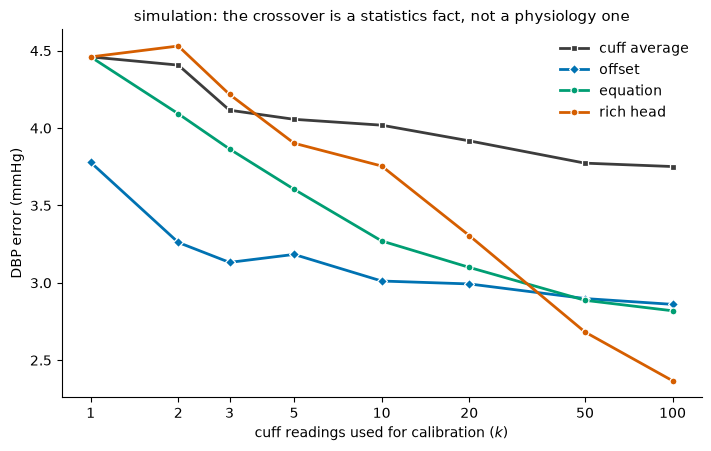

In [25]:
fig, ax = plt.subplots(figsize=(7.0, 4.4), constrained_layout=True)
style = {"cuff average": ("#3C3C3C", "s"), "offset": ("#0072B2", "D"),
         "equation": ("#009E73", "o"), "rich head": ("#D55E00", "o")}
for n, c in sim.items():
    col, mk = style[n]
    ax.plot(SIM_KS, [c[k] for k in SIM_KS], marker=mk, color=col, lw=2, ms=5,
            mec="white", mew=0.9, label=f"{n}")
ax.set_xscale("log"); ax.set_xticks(SIM_KS); ax.set_xticklabels(map(str, SIM_KS))
ax.minorticks_off()
ax.set_xlabel("cuff readings used for calibration ($k$)")
ax.set_ylabel("DBP error (mmHg)")
ax.set_title("simulation: the crossover is a statistics fact, not a physiology one",
             fontsize=11)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 6. The real curves

Same protocol, same solver, real data: PulseDB VitalDB CalFree, 144 held-out patients,
10-second segments at 125 Hz.

These numbers are read from the committed result JSONs rather than recomputed, because
recomputing needs `data/vitaldb_full_calfree.npz`, `data/_feat_full_ALLtrain.pkl` and
`models/transformer_ecgppg_full.pt` — all gitignored, so they live only on the machine that
ran the sweep. The JSONs below **are** in the repo.

In [26]:
DATA = ROOT / "data"
gbmj  = json.loads((DATA / "calib_gbm_finetune.json").read_text())
table = json.loads((DATA / "calib_finetune_table.json").read_text())

def as_curve(d):
    return {int(k): v for k, v in d.items() if np.isfinite(v)}

series = [
    ("cuff average (no waveform)",            as_curve(gbmj["cuff average"]),                      "#3C3C3C", "s", 1.7),
    ("equation · PTT (ECG→PPG)",              as_curve(table["PTT equation"]["curve"]),            "#C8C8C8", "o", 1.5),
    ("equation · PTT (PPG only, notch)",      as_curve(table["PPG-only dicrotic notch"]["curve"]), "#009E73", "o", 2.0),
    ("MAE transformer + fine-tuned head",     as_curve(gbmj["transformer + fine-tuned head"]),     "#D55E00", "o", 2.6),
    ("supervised transformer + head",         as_curve(table["transformer"]["curve"]),             "#E8A87C", "o", 1.5),
    ("LightGBM + post-hoc offset",            as_curve(gbmj["LightGBM waveform · offset"]),        "#7AA6D0", "D", 2.2),
    ("LightGBM + demographics, offset",       as_curve(gbmj["LightGBM waveform + demo · offset"]), "#0072B2", "D", 3.0),
]

ks_show = [1, 2, 3, 5, 10, 20, 50, 100]
print(f"{'arm':34}" + "".join(f"{k:>7}" for k in ks_show))
for nm, c, *_ in series:
    print(f"{nm:34}" + "".join(f"{c[k]:7.2f}" if k in c else "      ·" for k in ks_show))
print(f"\nno calibration at all (k=0): LightGBM {table['_k0']['waveform']:.2f}"
      f" | + demographics {table['_k0']['waveform+demo']:.2f} mmHg")

arm                                     1      2      3      5     10     20     50    100
cuff average (no waveform)              ·   6.47   6.30   5.96   5.84   5.71   5.58   5.58
equation · PTT (ECG→PPG)             7.14   7.96   7.57   6.41   6.08   5.74   5.65      ·
equation · PTT (PPG only, notch)     7.14   6.81   6.56   5.73   5.57   5.45   5.36      ·
MAE transformer + fine-tuned head       ·   7.69   6.15   5.55   4.87   4.46   3.77   3.31
supervised transformer + head        7.14   7.61   6.13   5.37   5.08   4.89   4.50      ·
LightGBM + post-hoc offset              ·   5.45   5.11   4.96   4.85   4.66   4.70   4.66
LightGBM + demographics, offset         ·   5.23   4.80   4.62   4.56   4.42   4.40   4.42

no calibration at all (k=0): LightGBM 7.60 | + demographics 7.42 mmHg


[done] /Users/masonkadem/Library/CloudStorage/OneDrive-McMasterUniversity/2026/mechdemo/figures/fig_calibration_strategy_from_json.png


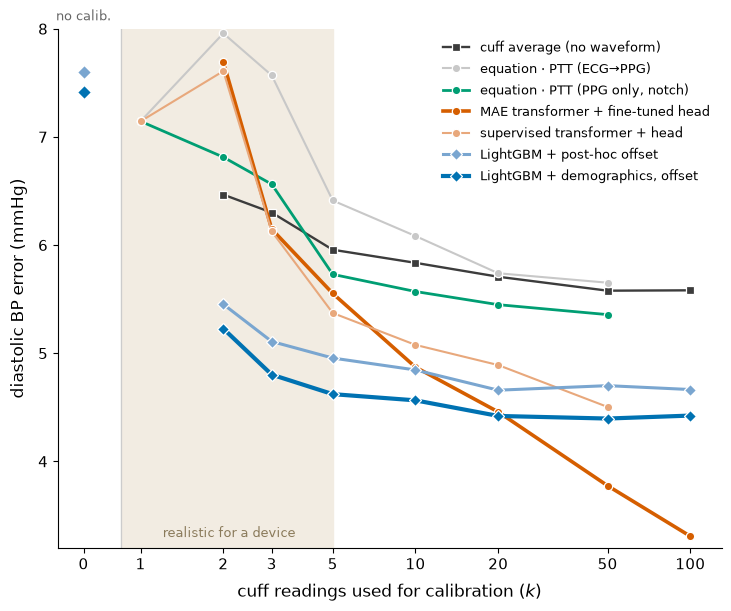

In [27]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.labelsize": 12,
                     "legend.fontsize": 9.5})
fig, ax = plt.subplots(figsize=(7.2, 6.0), constrained_layout=True)

ax.axvspan(0.85, 5, color="#F2ECE2", zorder=0)
ax.text(2.1, 3.30, "realistic for a device", ha="center", fontsize=9.5, color="#8A7A5A")

for nm, c, colr, mk, lw in series:
    xs = sorted(c)
    ax.plot(xs, [c[k] for k in xs], marker=mk, color=colr, lw=lw, ms=6,
            mec="white", mew=0.9, label=nm, clip_on=False, zorder=3)

X0 = 0.62                                   # a visually separate "no calibration" slot
for key, colr, mk in (("waveform", "#7AA6D0", "D"), ("waveform+demo", "#0072B2", "D")):
    ax.plot([X0], [table["_k0"][key]], marker=mk, color=colr, ms=7,
            mec="white", mew=0.9, clip_on=False, zorder=4)
ax.axvline(0.85, color="#CCCCCC", lw=0.9, zorder=1)
ax.text(X0, 8.05, "no calib.", ha="center", va="bottom", fontsize=9, color="#666")

ax.set_xscale("log"); ax.set_xticks([X0] + ks_show)
ax.set_xticklabels(["0"] + [str(k) for k in ks_show])
ax.minorticks_off(); ax.set_xlim(0.5, 130); ax.set_ylim(3.2, 8.0)
ax.set_xlabel("cuff readings used for calibration ($k$)", labelpad=8)
ax.set_ylabel("diastolic BP error (mmHg)", labelpad=8)
ax.legend(frameon=False, loc="upper right", labelspacing=0.55)
ax.spines[["top", "right"]].set_visible(False)

out = ROOT / "figures" / "fig_calibration_strategy_from_json.png"
fig.savefig(out, dpi=300); fig.savefig(out.with_suffix(".pdf"))
print(f"[done] {out}")
plt.show()

## 7. What the figure says

**In the shaded band — 1 to 5 readings, the only range a consumer device can ask for — a
gradient-boosted model with a *single* per-patient offset beats both the equation and the
fine-tuned transformer.** At `k = 2` the transformer sits at 7.69 mmHg: 2.2 behind LightGBM,
and *worse than ignoring the waveform entirely* and just averaging the two cuff readings
(6.47). By `k = 50` the ordering has reversed and the transformer is the best arm on the
plot at 3.77.

Both transformer arms are drawn, because they separate cleanly: the MAE-pretrained encoder
and the supervised one are indistinguishable at `k = 2` (7.69 vs 7.61 — neither can fit 129
numbers from 2 readings), but by `k = 50` pretraining is worth 0.73 mmHg (3.77 vs 4.50).
Pretraining buys you nothing at the cold start and a lot once calibration data arrives.

Three things follow.

1. **The crossover is about parameter count, not model class.** The transformer is not a
   worse model at `k = 2`; it is the same model asked to fit 129 numbers from 2 readings. The
   evidence for this reading is in [`data/calib_gbm_finetune.json`](../data/calib_gbm_finetune.json):
   *the same LightGBM* calibrated by an offset (1 number) scores 5.45 at `k = 2` and by a
   linear head (more numbers) scores 6.42 — the model is held fixed and only the calibration
   strategy moves, and the low-`k` ordering follows the parameter count.

2. **The equation is not embarrassed.** Two numbers, no GPU, no training corpus, and it
   beats a 396k-segment transformer at `k = 2` and `k = 3`, where a device actually lives.
   Its weakness is a ceiling, not a cold start: it stops improving once its 2 numbers are
   pinned down — from `k = 5` onwards the transformer is ahead, and the gap only widens.

3. **Demographics are nearly free.** Age, sex and BMI buy 0.23–0.33 mmHg, but only through
   the population model — a per-patient head cannot use them at all, since they have zero
   within-patient variance (`_demo_note.within_patient_sd ≈ 0.24`). That is a real asymmetry
   between the two calibration strategies, not a tuning detail.

## 8. What it does not say

- **Nothing about drift.** PulseDB shuffles segment order, so the gap axis cannot see
  calibration decaying over hours or days — the question a deployed device most needs
  answered. PTT itself is unaffected, being measured inside a segment.
- **These are anaesthetised operating-room recordings.** The pressure swings that make the
  stiffness mechanism strongest — exercise, posture — are absent, so this is not a verdict on
  ambulatory wearables.
- **The ECG→PPG equation arm is handicapped by instrumentation.** The PLETH channel lags the
  arterial line by a stable ~500 ms in raw VitalDB, which is why the PPG-only notch variant —
  a transit time measured *inside* one pulse, where no channel lag can reach it — is the
  equation arm worth reading.
- **PTT explains only 4–5% of within-subject DBP variance here**, under every transform
  tested and with invasive arterial-line PTT. Most of what calibration buys on this dataset
  is the personal offset, not the physiology.